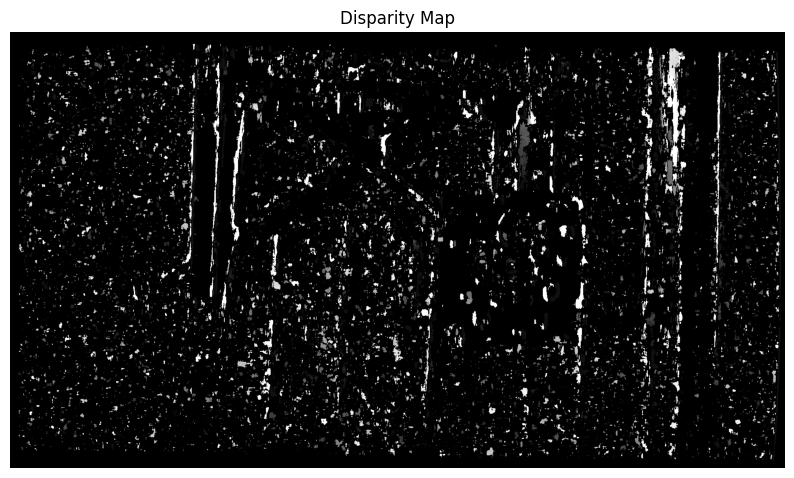

In [2]:
import cv2
import matplotlib.pyplot as plt

# Read left and right images from tsukuba folder
left_img = cv2.imread('cubic/rectified_left.png')
right_img = cv2.imread('cubic/rectified_right.png')

# Convert to grayscale
left_img = cv2.cvtColor(left_img, cv2.COLOR_RGB2GRAY)
right_img = cv2.cvtColor(right_img, cv2.COLOR_RGB2GRAY)

# Calculate disparity map
stereo = cv2.StereoBM.create(numDisparities=16, blockSize=15)
disparity = stereo.compute(left_img, right_img)

# Display disparity map
plt.figure(figsize=(10, 10))
plt.imshow(disparity, cmap='gray')
plt.title('Disparity Map')
plt.axis('off')
plt.show()

plt.show()

# SBM


In [90]:
WIDTH = 1920
HEIGHT = 1080

DOWNSAMPLE = 1

BLOCK_SIZE = 35
MIN_DISPARITY = 0
NUM_DISPARITIES = 16*20
TEXTURE_THRESHOLD = 1
UNIQUENESS_RATIO = 2
SPECKLE_RANGE = 1
SPECKLE_WINDOW = 3

In [91]:
class StereoBMMatcher:
    def __init__(self):
        self.width = WIDTH
        self.height = HEIGHT

        downsample = DOWNSAMPLE

        self.resize = (int(self.width / downsample), int(self.height / downsample))

        # Apply configuration settings
        self.sbm = cv2.StereoBM_create(
            numDisparities=NUM_DISPARITIES,
            blockSize=BLOCK_SIZE
        )
        self.sbm.setPreFilterType(1)
        self.sbm.setMinDisparity(MIN_DISPARITY)
        self.sbm.setNumDisparities(NUM_DISPARITIES)
        self.sbm.setTextureThreshold(TEXTURE_THRESHOLD)
        self.sbm.setUniquenessRatio(UNIQUENESS_RATIO)
        self.sbm.setSpeckleRange(SPECKLE_RANGE)
        self.sbm.setSpeckleWindowSize(SPECKLE_WINDOW)

    def process_pair(self, rectified_pair):
        left = cv2.resize(rectified_pair[0], self.resize)
        right = cv2.resize(rectified_pair[1], self.resize)

        disparity = self.sbm.compute(left, right)

        disparity = cv2.dilate(disparity, None, iterations=1)

        disparity = cv2.resize(disparity, (self.width, self.height))

        return disparity

(-0.5, 1919.5, 1079.5, -0.5)

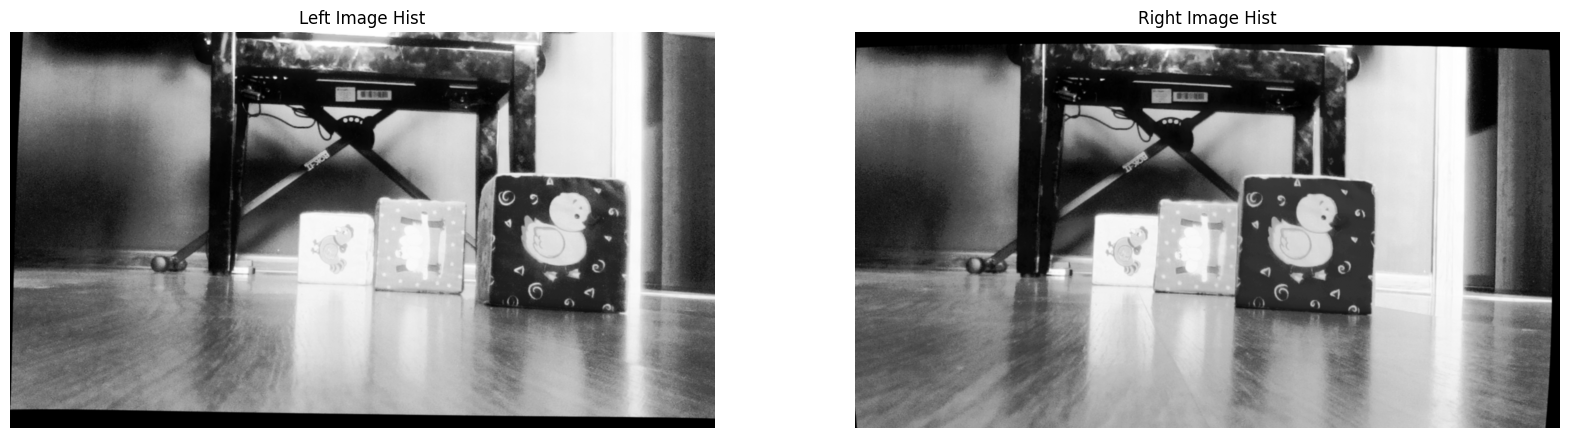

In [92]:
# Try equalize and filter
left_img_hist = cv2.equalizeHist(left_img)
right_img_hist = cv2.equalizeHist(right_img)

left_img_blur = cv2.GaussianBlur(left_img_hist, (5, 5), 0)
right_img_blur = cv2.GaussianBlur(right_img_hist, (5, 5), 0)

# Display images
plt.figure(figsize=(20, 10))
plt.subplot(1, 2, 1)
plt.imshow(left_img_blur, cmap='gray')
plt.title('Left Image Hist')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(right_img_blur, cmap='gray')
plt.title('Right Image Hist')
plt.axis('off')

CPU times: user 5.57 s, sys: 16.9 ms, total: 5.59 s
Wall time: 1.59 s


(-0.5, 1919.5, 1079.5, -0.5)

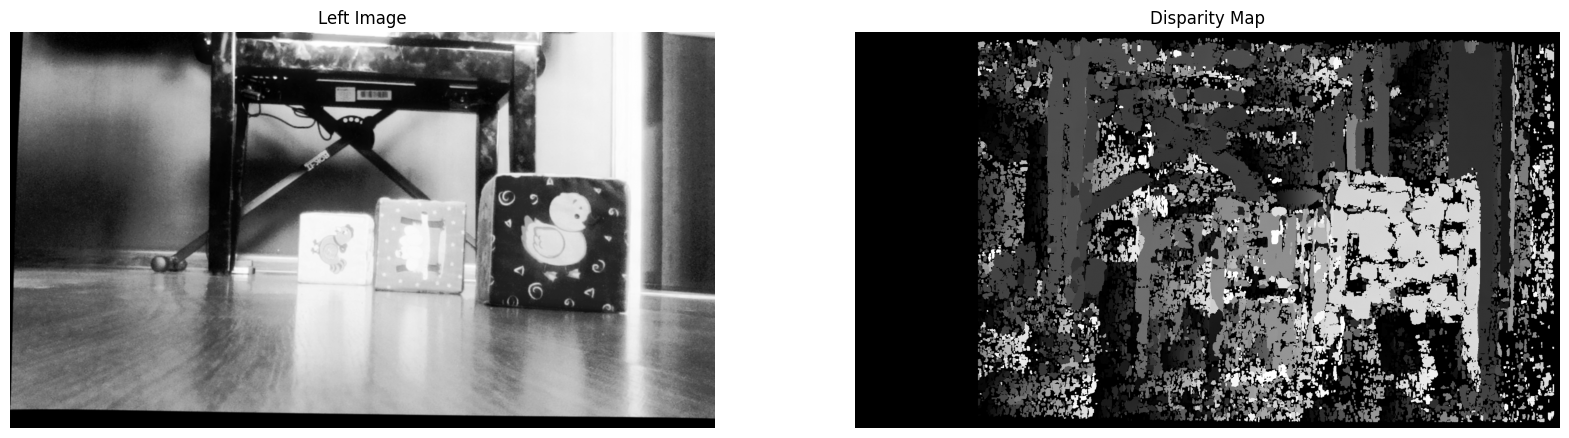

In [94]:
%%time

matcher = StereoBMMatcher()
rectified_pair = (left_img_blur, right_img_blur)
disparity = matcher.process_pair(rectified_pair)

plt.figure(figsize=(20, 10))
plt.subplot(1, 2, 1)
plt.imshow(left_img_blur, cmap='gray')
plt.title('Left Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(disparity, cmap='gray')
plt.title('Disparity Map')
plt.axis('off')

(-0.5, 1919.5, 1079.5, -0.5)

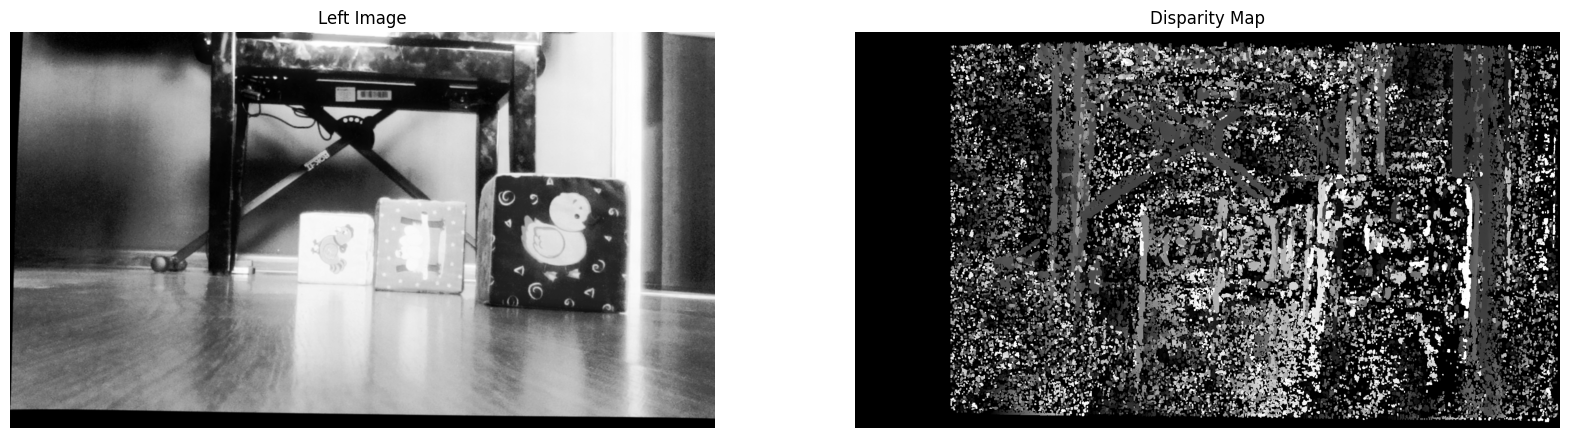

In [70]:
BLOCK_SIZE = 13  # Smaller block size to capture cube details better
NUM_DISPARITIES = 16*16  # Increased to better capture depth range
TEXTURE_THRESHOLD = 3  # Lower to be more sensitive to subtle patterns
UNIQUENESS_RATIO = 8  # Lower to allow more matches
SPECKLE_WINDOW = 2  # Reduced to preserve cube edges
SPECKLE_RANGE = 5  # Smaller range for more controlled speckle filtering

matcher = StereoBMMatcher()
rectified_pair = (left_img_blur, right_img_blur)
disparity = matcher.process_pair(rectified_pair)

plt.figure(figsize=(20, 10))
plt.subplot(1, 2, 1)
plt.imshow(left_img_blur, cmap='gray')
plt.title('Left Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(disparity, cmap='gray')
plt.title('Disparity Map')
plt.axis('off')

# SGBM


In [98]:
BLOCK_SIZE = 9
MIN_DISPARITY = 0
NUM_DISPARITIES = 16*10
P1_FACTOR = 8
P2_FACTOR = 32
DISP_12_MAX_DIFF = 1
PRE_FILTER_CAP = 0
UNIQUENESS_RATIO = 8
SPECKLE_RANGE = 2
SPECKLE_WINDOW = 10
DOWNSAMPLE = 2

In [99]:
class StereoSGBMMatcher:
    def __init__(self):
        self.width = WIDTH
        self.height = HEIGHT

        downsample = DOWNSAMPLE

        self.resize = (int(self.width / downsample), int(self.height / downsample))

        blockSize = BLOCK_SIZE

        # Apply configuration settings
        self.sbm = cv2.StereoSGBM_create(
            MIN_DISPARITY,
            NUM_DISPARITIES,
            blockSize,
            P1_FACTOR * 3 * blockSize * blockSize,
            P2_FACTOR * 3 * blockSize * blockSize,
            DISP_12_MAX_DIFF,
            PRE_FILTER_CAP,
            UNIQUENESS_RATIO,
            SPECKLE_WINDOW,
            SPECKLE_RANGE,
        )

    def process_pair(self, rectified_pair):
        left = cv2.resize(rectified_pair[0], self.resize)
        right = cv2.resize(rectified_pair[1], self.resize)

        disparity = self.sbm.compute(left, right)

        disparity = cv2.erode(disparity, None, iterations=1)
        disparity = cv2.dilate(disparity, None, iterations=1)

        disparity = cv2.resize(disparity, (self.width, self.height))

        return disparity

CPU times: user 553 ms, sys: 593 μs, total: 554 ms
Wall time: 549 ms


(-0.5, 1919.5, 1079.5, -0.5)

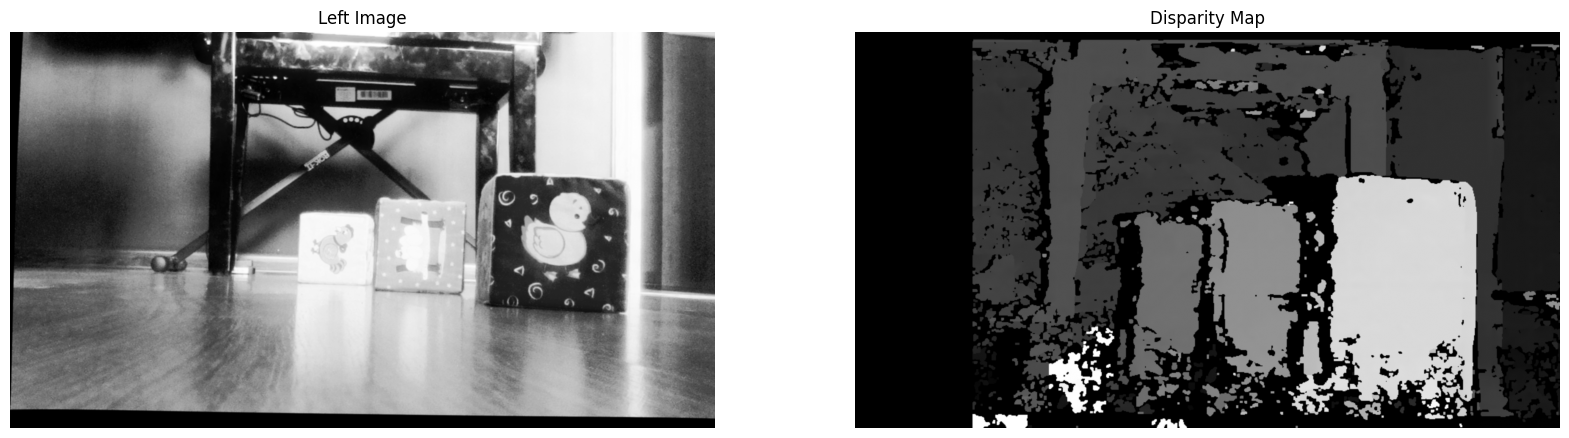

In [100]:
%%time

matcher = StereoSGBMMatcher()
rectified_pair = (left_img_blur, right_img_blur)
disparity = matcher.process_pair(rectified_pair)

plt.figure(figsize=(20, 10))
plt.subplot(121)
plt.imshow(left_img_blur, cmap='gray')
plt.title('Left Image')
plt.axis('off')
plt.subplot(122)
plt.imshow(disparity, cmap='gray')
plt.title('Disparity Map')
plt.axis('off')